# LM32 Lab — VaR, Expected Shortfall and Drawdown

Companion notebook to **From Calculus to Kelly, LM32**. It rebuilds the module's exhibits and computational examples from TR23, the TAIEX total-return index, and from the through case's eight rules. It refits LM26's GARCH forecasts, backtests six VaR models with the module's exact tests and with Kupiec's and Christoffersen's likelihood ratios, and resamples the rules' drawdowns. It solves the computational practice problems and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: TR23, 7 April 2025, the rules' returns and paths |
| 2 | Historical VaR and ES: Example 1, Example 2, Exhibit 2, NumPy's quantile methods; Problems 1 and 2 |
| 3 | Normal, Student t and Hill: Example 3, Exhibit 3, (32.4) by quadrature, Example 4; Problems 3 and 11 |
| 4 | Precision: (32.5), (32.6) and two bootstraps (Example 5), 250 returns; Problem 6 |
| 5 | Coherence: Example 6, (32.7) on TR23; Problems 7 and 12 |
| 6 | Filtered VaR: LM26's forecasts refitted, Example 7, Example 8; a portfolio by colouring; Problem 10 |
| 7 | Backtests: Exhibit 4, Exhibit 5, Exhibit 6, Exhibit 7, Example 9, the likelihood ratios; Problems 8 and 9 |
| 8 | Drawdowns: Exhibit 8, Exhibit 9, Exhibit 10, Example 10, Exhibit 11; intraday falls; Problem 4 |
| 9 | Extension: a 250-return backtest |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

On FinMind's free plan, run `uv run python data/fetch_finmind.py --exclude sectors_close/ --exclude vol4_settlement/ --exclude vol6/etf_snapshot` instead, as the book's Getting Started page says. This lab reads none of the excluded files. Part 8's intraday cell also reads three raw days of the 5-second TAIEX (`TaiwanVariousIndicators5Seconds`, a free dataset). Download them once with `uv run python data/fetch_intraday.py --series taiex5s --dates 2020-03-19,2024-08-05,2025-04-07` before `make_lab_data.py`; without them that cell says so and is skipped.

`data/` then holds these files, and the notebook reads nothing outside `data/`:

- `taiex_tr.csv`: `date` and `price`, the daily closes of the TAIEX total-return index (FinMind `TaiwanStockTotalReturnIndex`, data_id TAIEX), 2 January 2003 to 8 October 2026.
- `e5_estimation.csv` and `e5_wealth.csv`: E5's two frames (`base`, `date`, `fund`, `R`; the wealth frame adds `traded`).
- `rule_targets.csv`: the through case's trades (`data/vol5_rules.py`): rule, signal, trade date, the five target exposures, exposure, turnover and cost.
- `rule_wealth_net.csv`: the eight rules' net wealth after each day's trade, from the first trade's close.
- `taiex5s_2020-03-19.csv`, `taiex5s_2024-08-05.csv`, `taiex5s_2025-04-07.csv`: the TAIEX price index every 5 seconds on three days (used only for per-day statistics).

**Conventions (as in the module).** VaR and ES are positive for a loss at tail probability $u$ ("99%" is $u=0.01$). Historical VaR is $-R_{(\lceil uT\rceil)}$ (`method="inverted_cdf"`), historical ES is (32.2). Moments divide by $T$. An exceedance is $R_t<-\operatorname{VaR}_t-10^{-12}$; every count against a threshold uses the guard $10^{-12}$. Drawdowns run from the running peak, the starting 1 included. Each experiment creates `np.random.default_rng([e, 20261011])` once; batch standard errors use 20 consecutive batches (divisor 20).

In [1]:
import math
import time
import warnings
from datetime import date
from fractions import Fraction
from itertools import pairwise
from pathlib import Path

import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from arch import arch_model
from arch.bootstrap import StationaryBootstrap, optimal_block_length
from scipy import integrate, stats
from scipy.special import xlogy

DATA = Path("data")
EPS = 1e-12
SEED = 20261011
U, U2 = 0.01, 0.025
FUNDS = ["0050", "00646", "00679B", "00635U", "00642U"]
RULES = [f"R{k}" for k in range(1, 9)]
MODELS = ["HS", "N", "t", "EWMA", "GARCH-n", "GARCH-t"]
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def show(label, value, fmt, printed):
    # print a value next to the module's printed value and assert that they agree
    got = format(value, fmt)
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)


def jrank(u, n):
    return math.ceil(u * n - EPS)


def var_es(R, u):                         # (32.2): historical VaR and ES
    x = np.sort(R)
    T = len(x)
    j = int(np.ceil(u * T - 1e-12))       # j = ceil(uT), with a guard
    assert x[j - 1] == np.quantile(R, u, method="inverted_cdf")
    tail = x[: j - 1].sum() / T + x[j - 1] * (u - (j - 1) / T)
    return -x[j - 1], -tail / u


def mean_worst(R, u, floor=False):        # the means of the ceil(uT) (or floor(uT)) worst returns
    x = np.sort(R)
    k = math.floor(u * len(x)) if floor else jrank(u, len(x))
    return -x[:k].mean()


def normal_var_es(mu, s, u):              # (32.3)
    z = stats.norm.ppf(u)
    return -mu - s * z, -mu + s * stats.norm.pdf(z) / u


def t_var_es(nu, loc, sc, u):             # (32.4), with SciPy's scale sc = sigma sqrt((nu - 2)/nu)
    q = stats.t.ppf(u, nu)
    return -loc - sc * q, -loc + sc * (nu + q * q) * stats.t.pdf(q, nu) / ((nu - 1) * u)

## Part 1 — Data

TR23 has $T=5{,}849$ simple returns; years run from the close before the first return. The rules' wealth paths start at the cash of 1 before the first purchase, so a rule's 1,851 returns run from the session after the first trade.

In [2]:
tr = pl.read_csv(DATA / "taiex_tr.csv").sort("date")
dates_all = tr["date"].to_list()
price = tr["price"].to_numpy()
R = price[1:] / price[:-1] - 1
dates = dates_all[1:]
T = len(R)
years = (date.fromisoformat(dates_all[-1]) - date.fromisoformat(dates_all[0])).days / 365.25
A = T / years
show("T", T, ",", "5,849")
show("years from the close of 2 January 2003", years, ".4f", "23.7645")
show("A", A, ".2f", "246.12")
assert R.min() > -1
pos = {d: i for i, d in enumerate(dates)}
i7 = pos["2025-04-07"]
fr = [Fraction(f"{b:.2f}") / Fraction(f"{a:.2f}") - 1 for a, b in pairwise(price)]
assert min(range(T), key=lambda i: fr[i]) == i7 == int(np.argmin(R))       # exact minimum, from the closes
show("7 April 2025 (%)", -100 * R[i7], ".2f", "9.70")
show("its log return (%)", 100 * np.log1p(R[i7]), ".2f", "-10.20")
print("previous session", dates[i7 - 1], "| days without a session:",
      (date.fromisoformat(dates[i7]) - date.fromisoformat(dates[i7 - 1])).days - 1)

wn = pl.read_csv(DATA / "rule_wealth_net.csv").sort("rule", "date")
paths, ret = {}, {}
for k in RULES:
    w = wn.filter(pl.col("rule") == k)["wealth"].to_numpy()
    paths[k] = np.concatenate([[1.0], w])                  # the cash of 1, then wealth after each day's trade
    ret[k] = w[1:] / w[:-1] - 1
rdates = wn.filter(pl.col("rule") == "R1")["date"].to_list()
nR = len(ret["R1"])
show("the rules' returns", nR, ",", "1,851")
print("from", rdates[1], "to", rdates[-1])
show("years from the first trade", (date.fromisoformat(rdates[-1]) - date.fromisoformat(rdates[0])).days / 365.25,
     ".2f", "7.60")
assert all(p.min() > 0 for p in paths.values())           # no path reaches wealth <= 0

T: 5,849   [book: 5,849]
years from the close of 2 January 2003: 23.7645   [book: 23.7645]
A: 246.12   [book: 246.12]
7 April 2025 (%): 9.70   [book: 9.70]
its log return (%): -10.20   [book: -10.20]
previous session 2025-04-02 | days without a session: 4
the rules' returns: 1,851   [book: 1,851]
from 2019-03-05 to 2026-10-08
years from the first trade: 7.60   [book: 7.60]


## Part 2 — Historical VaR and ES (Example 1, Example 2, Exhibit 2)

`var_es` is Section 9's function: minus the $j$th smallest return and (32.2). It is compared with the means of the $\lceil uT\rceil$ and $\lfloor uT\rfloor$ worst returns.

five returns: VaR (%): 0.80   [book: 0.80]
five returns: ES (32.2) (%): 1.93   [book: 1.93]
mean of the 2 worst (%): 1.65   [book: 1.65]
mean of the floor(uT) = 1 worst (%): 2.50   [book: 2.50]
u = 0.001: j = 6
  VaR (%): 6.313   [book: 6.313]
  ES (%): 7.360   [book: 7.360]
u = 0.01: j = 59
  VaR (%): 3.567   [book: 3.567]
  ES (%): 4.689   [book: 4.689]
u = 0.025: j = 147
  VaR (%): 2.648   [book: 2.648]
  ES (%): 3.740   [book: 3.740]
u = 0.05: j = 293
  VaR (%): 1.862   [book: 1.862]
  ES (%): 2.969   [book: 2.969]
ES / VaR at 1%: 1.31   [book: 1.31]
mean of the 59 worst (%): 4.679   [book: 4.679]
mean of the floor(uT) = 58 worst (%): 4.699   [book: 4.699]
(32.2) at 1% (%): 4.689   [book: 4.689]
np.quantile, default 'linear' (%): -3.5668   [book: -3.5668]
np.quantile, 'inverted_cdf' (%): -3.5671   [book: -3.5671]
knowledge check: 50 returns at 1% give j = 1
Problem 1: the rank at T = 250: 3   [book: 3]
Problem 1: NumPy's default position from 0, (T - 1)u: 2.49   [book: 2.49]
  NumP

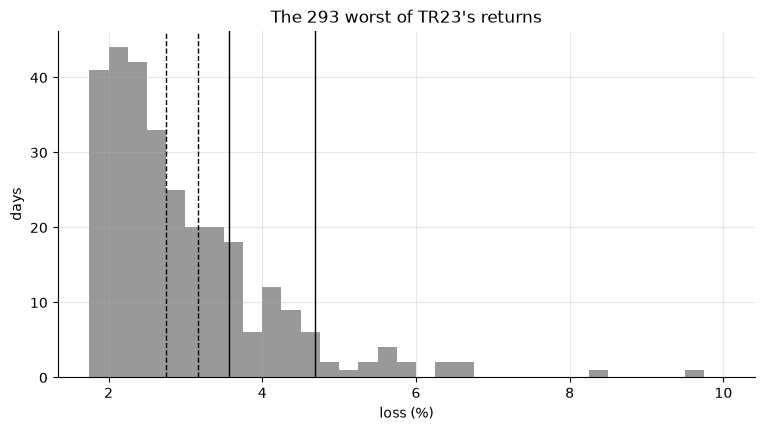

In [3]:
x5 = np.array([0.012, -0.008, 0.003, -0.025, 0.006])     # LM18's five returns
v, e = var_es(x5, 0.3)
show("five returns: VaR (%)", 100 * v, ".2f", "0.80")
show("five returns: ES (32.2) (%)", 100 * e, ".2f", "1.93")
show("mean of the 2 worst (%)", 100 * mean_worst(x5, 0.3), ".2f", "1.65")
show("mean of the floor(uT) = 1 worst (%)", 100 * mean_worst(x5, 0.3, floor=True), ".2f", "2.50")

for u, pv, pe in ((0.001, "6.313", "7.360"), (0.01, "3.567", "4.689"), (0.025, "2.648", "3.740"),
                  (0.05, "1.862", "2.969")):
    v, e = var_es(R, u)
    print(f"u = {u}: j = {jrank(u, T)}")
    show("  VaR (%)", 100 * v, ".3f", pv)
    show("  ES (%)", 100 * e, ".3f", pe)
v1, e1 = var_es(R, U)
show("ES / VaR at 1%", e1 / v1, ".2f", "1.31")
show("mean of the 59 worst (%)", 100 * mean_worst(R, U), ".3f", "4.679")
show("mean of the floor(uT) = 58 worst (%)", 100 * mean_worst(R, U, floor=True), ".3f", "4.699")
show("(32.2) at 1% (%)", 100 * e1, ".3f", "4.689")
show("np.quantile, default 'linear' (%)", 100 * np.quantile(R, U), ".4f", "-3.5668")
show("np.quantile, 'inverted_cdf' (%)", 100 * np.quantile(R, U, method="inverted_cdf"), ".4f", "-3.5671")
print("knowledge check: 50 returns at 1% give j =", jrank(0.01, 50))
show("Problem 1: the rank at T = 250", jrank(U, 250), "d", "3")
show("Problem 1: NumPy's default position from 0, (T - 1)u", 249 * U, ".2f", "2.49")
print("  NumPy's default on the ranks 1..250 gives rank", np.quantile(np.arange(1, 251), U),
      "| B, the midpoint of the 2nd and 3rd, is interpolated_inverted_cdf:",
      np.quantile(np.arange(1, 251), U, method="interpolated_inverted_cdf"))
xp2 = np.array([-0.061, -0.048, -0.042, -0.037, -0.033])   # Problem 2: the five worst of 180
es2 = -(xp2[:4].sum() / 180 + xp2[4] * (U2 - 4 / 180)) / U2
show("Problem 2: ES (32.2) (%)", 100 * es2, ".3f", "4.544")
show("Problem 2: B, the mean of the 5 worst (%)", -100 * xp2.mean(), ".3f", "4.420")
show("Problem 2: C, the mean of the 4 worst (%)", -100 * xp2[:4].mean(), ".3f", "4.700")

loss = -100 * np.sort(R)[: jrank(0.05, T)]
edges = np.arange(1.75, 10.0001, 0.25)
mu, s = R.mean(), R.std(ddof=0)
vn, en = normal_var_es(mu, s, U)
plt.hist(loss, bins=edges, color="0.6")
for xv, ls, lab in ((100 * v1, "-", "historical VaR"), (100 * e1, "-", "historical ES"),
                    (100 * vn, "--", "normal VaR"), (100 * en, "--", "normal ES")):
    plt.axvline(xv, ls=ls, color="k", lw=1)
plt.xlabel("loss (%)")
plt.ylabel("days")
plt.title("The 293 worst of TR23's returns")
plt.show()

## Part 3 — Normal, Student t and Hill (Example 3, Exhibit 3, Example 4)

The Student t is fitted by maximum likelihood on returns in percent; `scipy.stats.t.fit` returns $\nu$, the location and the scale $\sigma\sqrt{(\nu-2)/\nu}$. Hill's tail uses the losses of 3% or more (LM20's count), with the guard. The ten-session part compounds overlapping sums and draws ten days independently (experiment 7); Part 4 ends with its permutations and its bootstrap (experiments 9 and 10).

In [4]:
show("normal: VaR at 1% (%)", 100 * vn, ".2f", "2.75")
show("normal: ES at 1% (%)", 100 * en, ".2f", "3.16")
nu0, loc0, sc0 = stats.t.fit(100 * R)
show("t: nu", nu0, ".3f", "3.065")
show("t: location (%)", loc0, ".4f", "0.0997")
show("t: scale (%)", sc0, ".4f", "0.7761")
vt, et = t_var_es(nu0, loc0, sc0, U)
show("t: VaR at 1% (%)", vt, ".2f", "3.37")
show("t: ES at 1% (%)", et, ".2f", "5.19")
q = stats.t.ppf(U, nu0)
num = integrate.quad(lambda yv: yv * stats.t.pdf(yv, nu0), -np.inf, q, epsabs=1e-14, epsrel=1e-13)[0]
print(f"(32.4) against quadrature: difference {abs(-loc0 - sc0 * num / U - et):.1e} (below 1e-12)")
assert abs(-loc0 - sc0 * num / U - et) < 1e-12

L = -R
x0 = 0.03
tail = L[L >= x0 - EPS]
k = len(tail)
ah = k / np.sum(np.log(tail / x0))
show("Hill: k", k, "d", "108")
show("Hill: alpha_hat (Problem 11)", ah, ".3f", "3.634")
rows = []
for u in (0.001, 0.01, 0.025):
    hv, he = var_es(R, u)
    nv_, ne_ = normal_var_es(mu, s, u)
    tv_, te_ = t_var_es(nu0, loc0, sc0, u)
    hill = (x0 * (k / (u * T)) ** (1 / ah) if u <= k / T else None)
    rows.append({"u": u, "hist VaR": 100 * hv, "hist ES": 100 * he, "mean j worst": 100 * mean_worst(R, u),
                 "normal VaR": 100 * nv_, "normal ES": 100 * ne_, "t VaR": tv_, "t ES": te_,
                 "Hill VaR": None if hill is None else 100 * hill,
                 "Hill ES": None if hill is None else 100 * hill * ah / (ah - 1)})
print(pl.DataFrame(rows).with_columns(pl.exclude("u").round(2)))
show("Hill VaR at 1% (%)", rows[1]["Hill VaR"], ".2f", "3.55")
show("Hill ES at 1% (%)", rows[1]["Hill ES"], ".2f", "4.90")
show("Hill VaR at 0.1% (%)", rows[0]["Hill VaR"], ".2f", "6.69")
show("Hill ES at 0.1% (%)", rows[0]["Hill ES"], ".2f", "9.23")
show("t ES at 0.1% (unrounded fit) (%)", rows[0]["t ES"], ".2f", "11.37")

cs = np.concatenate([[0.0], np.cumsum(np.log1p(R))])
R10 = np.expm1(cs[10:] - cs[:-10])
show("ten sessions, 5,840 overlapping sums: VaR (%)", 100 * var_es(R10, U)[0], ".2f", "10.49")
show("sqrt(10) x one-day (%)", 100 * math.sqrt(10) * v1, ".2f", "11.28")
rb, sr = np.log1p(R).mean(), np.log1p(R).std(ddof=0)
show("iid normal log returns (%)", 100 * (1 - math.exp(10 * rb + math.sqrt(10) * sr * stats.norm.ppf(U))), ".2f", "8.02")
rng7 = np.random.default_rng([7, SEED])                    # experiment 7
R10iid = np.concatenate([np.prod(1 + R[rng7.integers(0, T, size=(5_000, 10))], axis=1) - 1 for _ in range(20)])
bq = np.array([np.quantile(c, U, method="inverted_cdf") for c in np.split(R10iid, 20)])
show("ten iid days drawn from TR23 (%)", -100 * np.quantile(R10iid, U, method="inverted_cdf"), ".2f", "8.75")
show("  batch SE (points)", 100 * bq.std() / math.sqrt(20), ".2f", "0.04")
c20 = np.concatenate([[0.0], np.cumsum(np.log1p(ret["R1"]))])
show("R1, 20 sessions (%)", 100 * var_es(np.expm1(c20[20:] - c20[:-20]), U)[0], ".2f", "8.66")
show("R1's one-day VaR (%)", 100 * var_es(ret["R1"], U)[0], ".3f", "2.102")
show("Problem 3: ES (%)", normal_var_es(0.05, 1.2, U)[1], ".3f", "3.148")

normal: VaR at 1% (%): 2.75   [book: 2.75]
normal: ES at 1% (%): 3.16   [book: 3.16]
t: nu: 3.065   [book: 3.065]
t: location (%): 0.0997   [book: 0.0997]
t: scale (%): 0.7761   [book: 0.7761]
t: VaR at 1% (%): 3.37   [book: 3.37]
t: ES at 1% (%): 5.19   [book: 5.19]
(32.4) against quadrature: difference 3.6e-15 (below 1e-12)
Hill: k: 108   [book: 108]
Hill: alpha_hat (Problem 11): 3.634   [book: 3.634]
shape: (3, 10)
┌───────┬──────────┬─────────┬──────────────┬───┬───────┬───────┬──────────┬─────────┐
│ u     ┆ hist VaR ┆ hist ES ┆ mean j worst ┆ … ┆ t VaR ┆ t ES  ┆ Hill VaR ┆ Hill ES │
│ ---   ┆ ---      ┆ ---     ┆ ---          ┆   ┆ ---   ┆ ---   ┆ ---      ┆ ---     │
│ f64   ┆ f64      ┆ f64     ┆ f64          ┆   ┆ f64   ┆ f64   ┆ f64      ┆ f64     │
╞═══════╪══════════╪═════════╪══════════════╪═══╪═══════╪═══════╪══════════╪═════════╡
│ 0.001 ┆ 6.31     ┆ 7.36    ┆ 7.33         ┆ … ┆ 7.58  ┆ 11.37 ┆ 6.69     ┆ 9.23    │
│ 0.01  ┆ 3.57     ┆ 4.69    ┆ 4.68         ┆ … ┆ 3.37  

## Part 4 — Precision (Example 5; Problem 6)

The ranks of (32.5) come from the binomial law of the count below the quantile. Experiment 5 resamples days independently, experiment 6 by the stationary bootstrap in LM22's draw order (start days, then uniforms), with LM22's block length 145. The function `stationary_idx` is checked against arch's `StationaryBootstrap` on twin generators. The last cell returns to Example 4: experiment 9 permutes TR23's days, which keeps the daily law and destroys the order, and experiment 10 resamples them by the same stationary bootstrap, for the precision of the overlapping ten-session VaR.

In [5]:
def ranks(n, u, level=0.95):
    a = (1 - level) / 2
    j1 = 0
    while stats.binom.cdf(j1, n, u) <= a:
        j1 += 1
    j2 = 1
    while stats.binom.cdf(j2 - 1, n, u) < 1 - a:
        j2 += 1
    lo = stats.binom.cdf(j1 - 1, n, u) if j1 >= 1 else 0.0
    return j1, j2, stats.binom.cdf(j2 - 1, n, u) - lo


xs = np.sort(R)
j1, j2, cov = ranks(T, U)
print("ranks", j1, j2)
show("interval: lower (%)", 100 * xs[j1 - 1], ".3f", "-4.016")
show("interval: upper (%)", 100 * xs[j2 - 1], ".3f", "-3.425")
show("coverage", cov, ".4f", "0.9587")
fh = (j2 - j1) / (T * 100 * (xs[j2 - 1] - xs[j1 - 1]))
show("spacing density (per point)", fh, ".4f", "0.0090")
show("SE by (32.6) (points)", math.sqrt(U * (1 - U) / T) / fh, ".3f", "0.145")
show("half the width / 1.96 (points)", 100 * (xs[j2 - 1] - xs[j1 - 1]) / 2 / 1.96, ".3f", "0.151")


def stationary_idx(rng, n, ell):
    start = rng.integers(n, size=n, dtype=np.int64)
    new = rng.random(n) <= 1.0 / ell
    new[0] = True
    first_ = np.flatnonzero(new)
    blk = np.cumsum(new) - 1
    return (start[first_][blk] + np.arange(n) - first_[blk]) % n


tw1, tw2 = np.random.default_rng([99, SEED]), np.random.default_rng([99, SEED])
sbt = StationaryBootstrap(145, R, seed=tw1)
assert all(np.array_equal(np.asarray(sbt.index), stationary_idx(tw2, T, 145)) for _ in sbt.bootstrap(3))
t0 = time.perf_counter()
rng5, rng6 = np.random.default_rng([5, SEED]), np.random.default_rng([6, SEED])
qi, qb = [], []
for _ in range(20):
    qi.append(np.quantile(R[rng5.integers(0, T, size=(500, T))], U, axis=1, method="inverted_cdf"))
    qb.append(np.quantile(R[np.stack([stationary_idx(rng6, T, 145) for _ in range(500)])], U, axis=1,
                          method="inverted_cdf"))
qi, qb = np.concatenate(qi), np.concatenate(qb)
print(f"experiments 5 and 6 in {time.perf_counter() - t0:.0f} s")


def batch_se_sd(v):
    b = np.array([c.std() for c in np.split(v, 20)])
    return b.std() / math.sqrt(20)


show("iid bootstrap SE (points)", 100 * qi.std(), ".3f", "0.119")
show("  its batch SE", 100 * batch_se_sd(qi), ".4f", "0.0014")
show("stationary bootstrap SE (points)", 100 * qb.std(), ".3f", "0.257")
show("  its batch SE", 100 * batch_se_sd(qb), ".4f", "0.0019")
show("ratio", qb.std() / qi.std(), ".1f", "2.2")

m1, m2, mc = ranks(T, 0.5)
show("median (%)", 100 * xs[jrank(0.5, T) - 1], ".4f", "0.0879")
show("median interval: lower (%)", 100 * xs[m1 - 1], ".3f", "0.069")
show("median interval: upper (%)", 100 * xs[m2 - 1], ".3f", "0.114")
show("median coverage", mc, ".4f", "0.9502")
fm = (m2 - m1) / (T * 100 * (xs[m2 - 1] - xs[m1 - 1]))
show("median spacing density (per point)", fm, ".4f", "0.5655")
show("median SE by (32.6) (points)", math.sqrt(0.25 / T) / fm, ".4f", "0.0116")

show("250 returns: 0.99^250 (%)", 100 * 0.99**250, ".2f", "8.11")
b1, b2, bc = ranks(250, U)
print("250 returns: j1 =", b1, "(no lower end), j2 =", b2)
show("  coverage", bc, ".3f", "0.986")
l250 = np.sort(R[-250:])
show("TR23's last 250: VaR (%)", -100 * l250[2], ".2f", "4.43")
show("  upper end (%)", 100 * l250[6], ".2f", "-3.61")
show("  worst (%)", 100 * l250[0], ".2f", "-6.46")
k1, k2, kc = ranks(1000, U)
print("Problem 6: ranks", k1, k2, "around R_(", jrank(U, 1000), ")")
show("Problem 6: coverage", kc, ".4f", "0.9761")

ranks 44 75
interval: lower (%): -4.016   [book: -4.016]
interval: upper (%): -3.425   [book: -3.425]
coverage: 0.9587   [book: 0.9587]
spacing density (per point): 0.0090   [book: 0.0090]
SE by (32.6) (points): 0.145   [book: 0.145]
half the width / 1.96 (points): 0.151   [book: 0.151]
experiments 5 and 6 in 2 s
iid bootstrap SE (points): 0.119   [book: 0.119]
  its batch SE: 0.0014   [book: 0.0014]
stationary bootstrap SE (points): 0.257   [book: 0.257]
  its batch SE: 0.0019   [book: 0.0019]
ratio: 2.2   [book: 2.2]
median (%): 0.0879   [book: 0.0879]
median interval: lower (%): 0.069   [book: 0.069]
median interval: upper (%): 0.114   [book: 0.114]
median coverage: 0.9502   [book: 0.9502]
median spacing density (per point): 0.5655   [book: 0.5655]
median SE by (32.6) (points): 0.0116   [book: 0.0116]
250 returns: 0.99^250 (%): 8.11   [book: 8.11]
250 returns: j1 = 0 (no lower end), j2 = 7
  coverage: 0.986   [book: 0.986]
TR23's last 250: VaR (%): 4.43   [book: 4.43]
  upper end (%

In [6]:
def v10_rows(X):                          # the 99% VaR of each row's 5,840 overlapping ten-session sums
    c = np.concatenate([np.zeros((X.shape[0], 1)), np.cumsum(np.log1p(X), axis=1)], axis=1)
    return -np.quantile(np.expm1(c[:, 10:] - c[:, :-10]), U, axis=1, method="inverted_cdf")


v10 = var_es(R10, U)[0]
t0 = time.perf_counter()
rng9 = np.random.default_rng([9, SEED])                    # experiment 9: permutations of TR23's days
P9 = np.concatenate([v10_rows(rng9.permuted(np.tile(R, (500, 1)), axis=1)) for _ in range(20)])
rng10 = np.random.default_rng([10, SEED])                  # experiment 10: the stationary bootstrap, l = 145
B10 = np.concatenate([v10_rows(R[np.stack([stationary_idx(rng10, T, 145) for _ in range(500)])]) for _ in range(20)])
print(f"experiments 9 and 10 in {time.perf_counter() - t0:.0f} s")
b9 = np.array([np.quantile(c, 0.5, method="inverted_cdf") for c in np.split(P9, 20)])
show("permutations: median ten-session VaR (%)", 100 * np.quantile(P9, 0.5, method="inverted_cdf"), ".1f", "8.7")
show("  its batch SE (points)", 100 * b9.std() / math.sqrt(20), ".3f", "0.004")
show("  permutations at or above the realized 10.49%", int(np.sum(P9 >= v10 - EPS)), "d", "2")
show("stationary bootstrap: SE of the 10.49% (points)", 100 * B10.std(), ".1f", "1.0")
show("  its batch SE (points)", 100 * batch_se_sd(B10), ".3f", "0.006")

experiments 9 and 10 in 5 s
permutations: median ten-session VaR (%): 8.7   [book: 8.7]
  its batch SE (points): 0.004   [book: 0.004]
  permutations at or above the realized 10.49%: 2   [book: 2]
stationary bootstrap: SE of the 10.49% (points): 1.0   [book: 1.0]
  its batch SE (points): 0.006   [book: 0.006]


## Part 5 — Coherence (Example 6; Problems 7 and 12)

The bonds' laws are discrete, so VaR and ES are computed exactly with `Fraction` by (32.1). The Rockafellar–Uryasev function of (32.7) is evaluated at every loss of TR23 (its kinks). Problem 12 solves the minimum-ES linear program of Section 9 on the through case's first window and checks it with HiGHS. The minimum-ES portfolio is an in-sample illustration.

In [7]:
def bonds(pd_, u, lgd=Fraction(-60, 100), gain=Fraction(2, 100)):
    # one bond and half in each of two independent bonds: VaR and ES (32.1) of the discrete laws
    one = sorted([(lgd, pd_), (gain, 1 - pd_)])
    half = sorted([(lgd, pd_**2), ((lgd + gain) / 2, 2 * pd_ * (1 - pd_)), (gain, (1 - pd_) ** 2)])

    def var_es_discrete(law):
        acc, tail = Fraction(0), Fraction(0)
        for x, p in law:
            take = min(p, u - acc)
            if take > 0:
                tail += take * x
                acc += take
            if acc >= u:
                return -x, -tail / u
        raise ValueError
    return var_es_discrete(one), var_es_discrete(half), 1 - (1 - pd_) ** 2


(v1b, e1b), (vhb, ehb), pany = bonds(Fraction(8, 1000), Fraction(1, 100))
show("one bond: VaR (%)", float(100 * v1b), ".2f", "-2.00")
show("one bond: ES (%)", float(100 * e1b), ".2f", "47.60")
show("half in each: Pr(some default) (%)", float(100 * pany), ".2f", "1.59")
show("half in each: VaR (%)", float(100 * vhb), ".2f", "29.00")
show("half in each: ES (%)", float(100 * ehb), ".2f", "29.20")
(v7a, e7a), (v7h, e7h), p7 = bonds(Fraction(4, 100), Fraction(5, 100))
show("Problem 7: VaR of half in each (%)", float(100 * v7h), ".2f", "29.00")
show("Problem 7: Pr(some default) (%)", float(100 * p7), ".2f", "7.84")
show("Problem 7: one bond's ES (%)", float(100 * e7a), ".2f", "47.60")
show("Problem 7: the mixture's ES (%)", float(100 * e7h), ".2f", "29.99")

Ls = np.sort(-100 * R)[::-1]                    # losses in %, largest first
csl = np.concatenate([[0.0], np.cumsum(Ls)])
kk = np.arange(1, T + 1)
F_ru = Ls + (csl[kk - 1] - (kk - 1) * Ls) / (U * T)
kmin = int(np.argmin(F_ru))
print("the minimum is at the loss of rank", kmin + 1)
show("its value (%)", F_ru[kmin], ".3f", "4.689")
show("at theta (%)", Ls[kmin], ".3f", "3.567")

one bond: VaR (%): -2.00   [book: -2.00]
one bond: ES (%): 47.60   [book: 47.60]
half in each: Pr(some default) (%): 1.59   [book: 1.59]
half in each: VaR (%): 29.00   [book: 29.00]
half in each: ES (%): 29.20   [book: 29.20]
Problem 7: VaR of half in each (%): 29.00   [book: 29.00]
Problem 7: Pr(some default) (%): 7.84   [book: 7.84]
Problem 7: one bond's ES (%): 47.60   [book: 47.60]
Problem 7: the mixture's ES (%): 29.99   [book: 29.99]
the minimum is at the loss of rank 59
its value (%): 4.689   [book: 4.689]
at theta (%): 3.567   [book: 3.567]


In [8]:
el = pl.read_csv(DATA / "e5_estimation.csv", schema_overrides={"fund": pl.Utf8, "base": pl.Utf8, "date": pl.Utf8})
est = el.pivot(on="fund", index="date", values="R").sort("date").select("date", *FUNDS)
win = est.filter(pl.col("date") <= "2019-02-27").tail(504)
print("first window", win["date"][0], "..", win["date"][-1], "rows", win.height)
xw = win.select(FUNDS).to_numpy()


def min_es(Rw, u):                        # (32.7) as a linear program (Section 9)
    T, N = Rw.shape                       # Rw: T x N returns in percent
    w, th, s = cp.Variable(N), cp.Variable(), cp.Variable(T)
    cons = [s >= 0, s + Rw @ w + th >= 0, w >= 0, cp.sum(w) == 1]
    prob = cp.Problem(cp.Minimize(th + cp.sum(s) / (u * T)), cons)
    prob.solve(solver=cp.CLARABEL, tol_gap_abs=1e-12,
               tol_gap_rel=1e-12, tol_feas=1e-12)
    assert prob.status == "optimal" and w.value is not None
    return w.value, prob.value


with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)        # cvxpy's bound propagation; the solve is unaffected
    w_es, obj = min_es(100 * xw, U2)
    wh, thh = cp.Variable(5), cp.Variable()
    lp2 = cp.Problem(cp.Minimize(thh + cp.sum(cp.pos(-100 * xw @ wh - thh)) / (U2 * 504)), [cp.sum(wh) == 1, wh >= 0])
    lp2.solve(solver=cp.HIGHS)
assert lp2.status == "optimal" and wh.value is not None
print(f"HiGHS: objective gap {abs(lp2.value - obj):.1e}, weight gap {np.abs(wh.value - w_es).max():.1e}")
w_es = np.where(np.abs(w_es) < 1e-6, 0.0, w_es)
for f_, wv, p_ in zip(FUNDS, w_es, ["0.078", "0.203", "0.398", "0.290", "0.030"]):
    show(f"Problem 12: weight of {f_}", wv, ".3f", p_)
show("Problem 12: ES (%)", obj, ".3f", "0.857")
show("Problem 12: VaR at the solution (%)", 100 * var_es(xw @ w_es, U2)[0], ".3f", "0.693")
tg = pl.read_csv(DATA / "rule_targets.csv", schema_overrides={"signal": pl.Utf8, "trade": pl.Utf8})
w3 = tg.filter((pl.col("rule") == "R3") & (pl.col("signal") == "2019-02-27")).select(FUNDS).to_numpy()[0]
show("Problem 12: R3's ES (%)", 100 * var_es(xw @ w3, U2)[1], ".3f", "0.880")
show("Problem 12: R1's ES (%)", 100 * var_es(xw @ np.full(5, 0.2), U2)[1], ".3f", "1.303")

first window 2017-02-13 .. 2019-02-27 rows 504
HiGHS: objective gap 1.3e-13, weight gap 6.2e-14
Problem 12: weight of 0050: 0.078   [book: 0.078]
Problem 12: weight of 00646: 0.203   [book: 0.203]
Problem 12: weight of 00679B: 0.398   [book: 0.398]
Problem 12: weight of 00635U: 0.290   [book: 0.290]
Problem 12: weight of 00642U: 0.030   [book: 0.030]
Problem 12: ES (%): 0.857   [book: 0.857]
Problem 12: VaR at the solution (%): 0.693   [book: 0.693]
Problem 12: R3's ES (%): 0.880   [book: 0.880]
Problem 12: R1's ES (%): 1.303   [book: 1.303]


## Part 6 — Filtered VaR (Example 7, Example 8; Problem 10)

LM26's design is rebuilt here: GARCH(1,1) with normal and with $t$ innovations is refitted at each month's first session on the previous 1,231 log returns in percent, started from arch's backcast; EWMA has $\lambda=0.94$, mean zero, and starts at the mean of $y_t^2$ over the first 246 returns. The $t$ model of the backtest refits `t.fit` at the same sessions. The next cell runs 452 GARCH fits and 226 $t$ fits (about ten seconds on the author's machine).

In [9]:
y = 100 * np.log1p(R)                     # log returns in percent
W = round(5 * A)
month = [d[:7] for d in dates]
starts = [i for i in range(T) if i == 0 or month[i] != month[i - 1]]
first = next(i for i in starts if i >= W)
oos = np.arange(first, T)
show("window", W, ",", "1,231")
show("forecast days", len(oos), ",", "4,609")
print("first forecast day", dates[first])


def fit(xv, dist):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        res = arch_model(xv, mean="Constant", vol="GARCH", p=1, q=1, dist=dist).fit(disp="off", cov_type="robust")
    assert res.convergence_flag == 0
    return res


def backcast(e):
    wb = 0.94 ** np.arange(min(75, len(e)))
    return float(np.sum(e[: len(wb)] ** 2 * wb / wb.sum()))


def garch_filter(om, al, be, e, bc):
    s2 = np.empty(len(e) + 1)
    s2[0] = om + (al + be) * bc
    for t in range(len(e)):
        s2[t + 1] = om + al * e[t] ** 2 + be * s2[t]
    return s2


t0 = time.perf_counter()
s2g = {"normal": np.full(T, np.nan), "t": np.full(T, np.nan)}
par = {"normal": np.full((T, 5), np.nan), "t": np.full((T, 5), np.nan)}
tday = np.full((T, 3), np.nan)
mstarts = [s_ for s_ in starts if s_ >= first]
for k_, s_ in enumerate(mstarts):
    e_end = mstarts[k_ + 1] if k_ + 1 < len(mstarts) else T
    wy = y[s_ - W:s_]
    bcw = backcast(wy - wy.mean())
    for dist in ("normal", "t"):
        p_ = fit(wy, dist).params.to_numpy()
        s2g[dist][s_:e_end] = garch_filter(p_[1], p_[2], p_[3], y[s_ - W:e_end] - p_[0], bcw)[W:W + e_end - s_]
        par[dist][s_:e_end, : len(p_)] = p_
    tday[s_:e_end] = stats.t.fit(100 * R[s_ - W:s_])
ew = np.empty(T + 1)
ew[0] = np.mean(y[:246] ** 2)
for t in range(T):
    ew[t + 1] = 0.94 * ew[t] + 0.06 * y[t] ** 2
print(f"{len(mstarts)} refits per law in {time.perf_counter() - t0:.0f} s")
show("EWMA sigma for 7 April (%)", math.sqrt(ew[i7]), ".4f", "1.5605")
show("GARCH-n sigma for 7 April (%)", math.sqrt(s2g["normal"][i7]), ".4f", "1.7222")
show("GARCH-t sigma for 7 April (%)", math.sqrt(s2g["t"][i7]), ".4f", "1.7040")
pn, pt = par["normal"][i7], par["t"][i7]
show("GARCH-n refit's mean (%)", pn[0], ".4f", "0.1020")
show("GARCH-t refit's mean (%)", pt[0], ".4f", "0.1190")
show("GARCH-t refit's nu", pt[4], ".2f", "6.39")

window: 1,231   [book: 1,231]
forecast days: 4,609   [book: 4,609]
first forecast day 2008-01-02
226 refits per law in 9 s
EWMA sigma for 7 April (%): 1.5605   [book: 1.5605]
GARCH-n sigma for 7 April (%): 1.7222   [book: 1.7222]
GARCH-t sigma for 7 April (%): 1.7040   [book: 1.7040]
GARCH-n refit's mean (%): 0.1020   [book: 0.1020]
GARCH-t refit's mean (%): 0.1190   [book: 0.1190]
GARCH-t refit's nu: 6.39   [book: 6.39]


In [10]:
def var_day(m, t, u=U):
    wr = R[t - W:t]
    if m == "HS":
        return var_es(wr, u)[0]
    if m == "N":
        return normal_var_es(wr.mean(), wr.std(ddof=0), u)[0]
    if m == "t":
        return t_var_es(*tday[t], u)[0] / 100
    if m == "EWMA":
        return 1 - math.exp(math.sqrt(ew[t]) * stats.norm.ppf(u) / 100)
    if m == "GARCH-n":
        return 1 - math.exp((par["normal"][t, 0] + math.sqrt(s2g["normal"][t]) * stats.norm.ppf(u)) / 100)
    nv = par["t"][t, 4]
    return 1 - math.exp((par["t"][t, 0] + math.sqrt(s2g["t"][t]) * stats.t.ppf(u, nv) * math.sqrt((nv - 2) / nv)) / 100)


def es_day(m, t, u=U):
    # ES of the simple return R = e^r - 1 under each model, (32.1)
    wr = R[t - W:t]
    if m == "HS":
        return var_es(wr, u)[1]
    if m == "N":
        return normal_var_es(wr.mean(), wr.std(ddof=0), u)[1]
    if m == "t":
        return t_var_es(*tday[t], u)[1] / 100
    if m in ("EWMA", "GARCH-n"):
        g0 = 0.0 if m == "EWMA" else par["normal"][t, 0] / 100
        s0 = math.sqrt(ew[t] if m == "EWMA" else s2g["normal"][t]) / 100
        return 1 - math.exp(g0 + s0 * s0 / 2) * stats.norm.cdf(stats.norm.ppf(u) - s0) / u
    nv = par["t"][t, 4]
    g0, s0, c0 = par["t"][t, 0] / 100, math.sqrt(s2g["t"][t]) / 100, math.sqrt((nv - 2) / nv)
    qy = stats.t.ppf(u, nv)
    return 1 - integrate.quad(lambda v: math.exp(g0 + s0 * c0 * v) * stats.t.pdf(v, nv), -np.inf, qy)[0] / u


VAR = {m: np.array([var_day(m, int(t)) for t in oos]) for m in MODELS}
k7 = int(i7 - first)
for m, pv, pe, pr in (("HS", "3.53", "4.58", "2.75"), ("N", "2.66", "3.06", "3.65"), ("t", "3.08", "4.38", "3.15"),
                      ("EWMA", "3.57", "4.07", "2.72"), ("GARCH-n", "3.83", "4.39", "2.53"),
                      ("GARCH-t", "4.14", "5.26", "2.34")):
    show(f"{m}: 99% VaR for 7 April (%)", 100 * VAR[m][k7], ".2f", pv)
    show(f"{m}: 99% ES for 7 April (%)", 100 * es_day(m, i7), ".2f", pe)
    show(f"{m}: loss / VaR", -R[i7] / VAR[m][k7], ".2f", pr)
zn = (y[i7] - pn[0]) / math.sqrt(s2g["normal"][i7])
zt_ = (y[i7] - pt[0]) / math.sqrt(s2g["t"][i7])
p_n = stats.norm.cdf(zn)
p_t = stats.t.cdf(zt_ / math.sqrt((pt[4] - 2) / pt[4]), pt[4])
show("GARCH-n: standardized loss", zn, ".2f", "-5.98")
print(f"GARCH-n: probability {p_n:.1e}, once in {1 / (p_n * A) / 1e6:.1f} million years of {A:.2f} sessions")
show("GARCH-t: standardized loss", zt_, ".2f", "-6.06")
show("GARCH-t: once in (sessions)", round(1 / p_t), ",", "8,014")
show("GARCH-t: once in (years)", 1 / (p_t * A), ".1f", "32.6")

HS: 99% VaR for 7 April (%): 3.53   [book: 3.53]
HS: 99% ES for 7 April (%): 4.58   [book: 4.58]
HS: loss / VaR: 2.75   [book: 2.75]
N: 99% VaR for 7 April (%): 2.66   [book: 2.66]
N: 99% ES for 7 April (%): 3.06   [book: 3.06]
N: loss / VaR: 3.65   [book: 3.65]
t: 99% VaR for 7 April (%): 3.08   [book: 3.08]
t: 99% ES for 7 April (%): 4.38   [book: 4.38]
t: loss / VaR: 3.15   [book: 3.15]
EWMA: 99% VaR for 7 April (%): 3.57   [book: 3.57]
EWMA: 99% ES for 7 April (%): 4.07   [book: 4.07]
EWMA: loss / VaR: 2.72   [book: 2.72]
GARCH-n: 99% VaR for 7 April (%): 3.83   [book: 3.83]
GARCH-n: 99% ES for 7 April (%): 4.39   [book: 4.39]
GARCH-n: loss / VaR: 2.53   [book: 2.53]
GARCH-t: 99% VaR for 7 April (%): 4.14   [book: 4.14]
GARCH-t: 99% ES for 7 April (%): 5.26   [book: 5.26]
GARCH-t: loss / VaR: 2.34   [book: 2.34]
GARCH-n: standardized loss: -5.98   [book: -5.98]
GARCH-n: probability 1.1e-09, once in 3.7 million years of 246.12 sessions
GARCH-t: standardized loss: -6.06   [book: -6.0

In [11]:
# experiment 1: ten GARCH-t sessions from 2 April (the 1 April refit), each step drawing all paths' innovations
mu_, om, al, be, nu7 = pt
sct = math.sqrt((nu7 - 2) / nu7)
s2_0 = s2g["t"][i7]
rng1 = np.random.default_rng([1, SEED])
B1 = 100_000
tot, s2v, t1 = np.zeros(B1), np.full(B1, s2_0), np.empty((10, B1))
for step in range(10):
    t1[step] = rng1.standard_t(nu7, size=B1)
    e_ = np.sqrt(s2v) * t1[step] * sct
    tot += mu_ + e_
    s2v = om + al * e_**2 + be * s2v
s2_bar = om / (1 - al - be)
s2_det = s2_bar + (al + be) ** np.arange(10) * (s2_0 - s2_bar)
R10mc = np.expm1(tot / 100)
R10c = np.expm1((mu_ + math.sqrt(s2_0) * t1 * sct).sum(axis=0) / 100)
R10d = np.expm1((mu_ + np.sqrt(s2_det)[:, None] * t1 * sct).sum(axis=0) / 100)


def q01(v):
    return -np.quantile(v, U, method="inverted_cdf")


def bse(v):
    b = np.array([-q01(c) for c in np.split(v, 20)])
    return b.std() / math.sqrt(20)


show("ten-day VaR, full GARCH-t (%)", 100 * q01(R10mc), ".1f", "10.5")
show("  batch SE (points)", 100 * bse(R10mc), ".2f", "0.07")
show("sqrt(10) x one-day GARCH-t (%)", 100 * math.sqrt(10) * VAR["GARCH-t"][k7], ".2f", "13.10")
show("realized loss, 7-18 April (%)", -100 * (np.prod(1 + R[i7:i7 + 10]) - 1), ".2f", "8.92")
show("constant sigma (%)", 100 * q01(R10c), ".1f", "10.9")
show("  batch SE (points)", 100 * bse(R10c), ".2f", "0.05")
show("(26.4)'s deterministic path (%)", 100 * q01(R10d), ".1f", "9.9")
show("  batch SE (points)", 100 * bse(R10d), ".2f", "0.06")
show("the fit's unconditional SD (% a day)", math.sqrt(s2_bar), ".3f", "1.116")
show("persistence", al + be, ".3f", "0.922")
bd = np.array([q01(a) - q01(b) for a, b in zip(np.split(R10mc, 20), np.split(R10d, 20))])
show("full minus deterministic (points)", 100 * (q01(R10mc) - q01(R10d)), ".1f", "0.6")
show("  batch SE of the difference", 100 * bd.std() / math.sqrt(20), ".2f", "0.04")

# Problem 10: importance sampling (18.7), experiment 2
a = -zn
rng2 = np.random.default_rng([2, SEED])
Z = rng2.standard_normal(10_000)
wis = (Z <= 0) * np.exp(a * Z - a * a / 2)
show("Problem 10: a", a, ".4f", "5.9836")
print(f"Problem 10: estimate {wis.mean():.2e} +- {wis.std() / 100:.0e}; exact {stats.norm.cdf(-a):.3e}")
show("  plain draws expected in the tail", 10_000 * stats.norm.cdf(-a), ".6f", "0.000011")
show("  shifted draws in the tail", int((Z <= 0).sum()), ",", "4,927")
p_ = stats.norm.cdf(-a)
print(f"  variance ratio {p_ * (1 - p_) / (math.exp(a * a) * stats.norm.cdf(-2 * a) - p_**2):.2e}")

# The same weighted draws also give a far quantile, the inverse question (a model illustration, no module number):
# the smallest shifted draw at which the weighted tail sum reaches 1e-9 estimates Phi^-1(1e-9), and (32.8) turns it
# into GARCH-n's one-day VaR at that tail probability.
xd = Z - a                                                 # the shifted draws, mean -a
w_all = np.exp(a * Z - a * a / 2)                          # each draw's weight phi(x) / phi(x + a)
order = np.argsort(xd)
cum_w = np.cumsum(w_all[order]) / len(Z)
z_is = xd[order][int(np.searchsorted(cum_w, 1e-9))]
z_ex = stats.norm.ppf(1e-9)
print(f"importance sampling: the 1e-9 quantile of Z is {z_is:.3f}, against the exact {z_ex:.3f}; GARCH-n's VaR at "
      f"u = 1e-9 is {100 * (1 - math.exp((pn[0] + math.sqrt(s2g['normal'][i7]) * z_is) / 100)):.2f}% "
      f"(exact {100 * (1 - math.exp((pn[0] + math.sqrt(s2g['normal'][i7]) * z_ex) / 100)):.2f}%)")

ten-day VaR, full GARCH-t (%): 10.5   [book: 10.5]
  batch SE (points): 0.07   [book: 0.07]
sqrt(10) x one-day GARCH-t (%): 13.10   [book: 13.10]
realized loss, 7-18 April (%): 8.92   [book: 8.92]
constant sigma (%): 10.9   [book: 10.9]
  batch SE (points): 0.05   [book: 0.05]
(26.4)'s deterministic path (%): 9.9   [book: 9.9]
  batch SE (points): 0.06   [book: 0.06]
the fit's unconditional SD (% a day): 1.116   [book: 1.116]
persistence: 0.922   [book: 0.922]
full minus deterministic (points): 0.6   [book: 0.6]
  batch SE of the difference: 0.04   [book: 0.04]
Problem 10: a: 5.9836   [book: 5.9836]
Problem 10: estimate 1.15e-09 +- 3e-11; exact 1.091e-09
  plain draws expected in the tail: 0.000011   [book: 0.000011]
  shifted draws in the tail: 4,927   [book: 4,927]
  variance ratio 1.34e+08
importance sampling: the 1e-9 quantile of Z is -6.004, against the exact -5.998; GARCH-n's VaR at u = 1e-9 is 9.73% (exact 9.72%)


A portfolio's Monte Carlo VaR colours standard normal draws with LM12's Cholesky factor, as (16.7) states. Here R1's equal weights on the first window's sample mean and covariance (divisor $T$) give a normal model, whose VaR (32.3) uses $\sigma_p$. The draws (experiment 8, 100,000) should agree with it to their standard error. This is a model illustration, not a number of the module.

In [12]:
mw, Sw = xw.mean(axis=0), np.cov(xw, rowvar=False, ddof=0)
Lc = np.linalg.cholesky(Sw)
w1 = np.full(5, 0.2)
rng8 = np.random.default_rng([8, SEED])
Rp = (mw + rng8.standard_normal((100_000, 5)) @ Lc.T) @ w1
sp_ = math.sqrt(w1 @ Sw @ w1)
se_q = math.sqrt(U * (1 - U) / 100_000) / (stats.norm.pdf(stats.norm.ppf(U)) / sp_)     # (32.6) for the draws
print(f"normal model: VaR {100 * normal_var_es(w1 @ mw, sp_, U)[0]:.3f}%; coloured draws "
      f"{-100 * np.quantile(Rp, U, method='inverted_cdf'):.3f}% (SE by (32.6) {100 * se_q:.3f} points)")

normal model: VaR 1.086%; coloured draws 1.092% (SE by (32.6) 0.006 points)


## Part 7 — Backtests (Exhibit 4, Exhibit 5, Exhibit 6, Exhibit 7, Example 9; Problems 8 and 9)

The exact tests are LM21's: a one-sided binomial upper tail for the count, and for independence the count of exceedances followed by another against $\operatorname{Bin}(\text{trials},x/n)$. The likelihood ratios follow Kupiec (1995) and Christoffersen (1998). Christoffersen's indicator is 1 inside the interval; this lab codes an exceedance as 1 instead, which leaves the three statistics unchanged. They are written out in the pair counts $n_{00}$, $n_{01}$, $n_{10}$, $n_{11}$ and the rates $\hat p=x/n$, $\hat p_{01}$, $\hat p_{11}$, $\hat p_2$.

expected exceedances: 46.09   [book: 46.09]
Basel 250 days: Pr(X <= 0) (%): 8.11   [book: 8.11]
Basel 250 days: Pr(X <= 1) (%): 28.58   [book: 28.58]
Basel 250 days: Pr(X <= 2) (%): 54.32   [book: 54.32]
Basel 250 days: Pr(X <= 3) (%): 75.81   [book: 75.81]
Basel 250 days: Pr(X <= 4) (%): 89.22   [book: 89.22]
Basel 250 days: Pr(X <= 5) (%): 95.88   [book: 95.88]
zones from: 250 days (5, 10) | 500 days (9, 15) | 4,609 days (57, 73)
shape: (6, 6)
┌─────────┬─────┬────────┬────────────┬────────┬────────────┐
│ model   ┆ x   ┆ rate % ┆ Pr(X>=x)   ┆ zone   ┆ mean VaR % │
│ ---     ┆ --- ┆ ---    ┆ ---        ┆ ---    ┆ ---        │
│ str     ┆ i64 ┆ f64    ┆ f64        ┆ str    ┆ f64        │
╞═════════╪═════╪════════╪════════════╪════════╪════════════╡
│ HS      ┆ 56  ┆ 1.22   ┆ 0.084847   ┆ green  ┆ 3.24       │
│ N       ┆ 110 ┆ 2.39   ┆ 6.5465e-16 ┆ red    ┆ 2.58       │
│ t       ┆ 69  ┆ 1.5    ┆ 0.000914   ┆ yellow ┆ 3.09       │
│ EWMA    ┆ 103 ┆ 2.23   ┆ 2.7338e-13 ┆ red    ┆ 2.51 

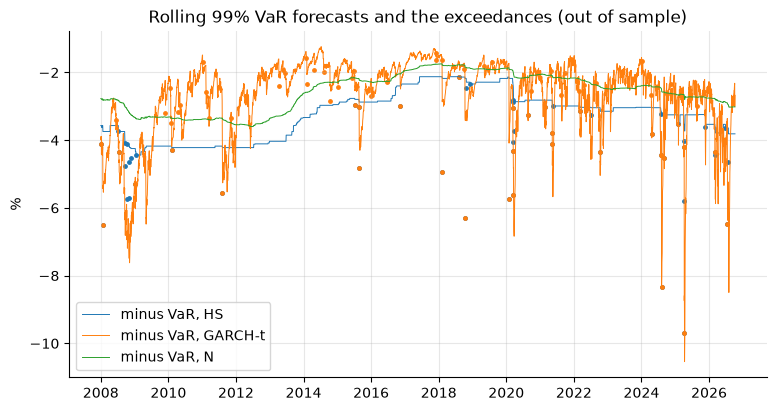

Problem 8: Pr(X <= 9), 500 days: 0.9689   [book: 0.9689]
Problem 8: Pr(X >= 9): 0.0671   [book: 0.0671]
Problem 9: expected: 1.77   [book: 1.77]
Problem 9: Pr(Bin(59, 0.03) >= 6): 0.0084   [book: 0.0084]


In [13]:
Ro = R[oos]
n = len(oos)
show("expected exceedances", n * U, ".2f", "46.09")


def zones(nn):
    yel = next(x for x in range(nn + 1) if stats.binom.cdf(x, nn, U) >= 0.95)
    red = next(x for x in range(nn + 1) if stats.binom.cdf(x, nn, U) >= 0.9999)
    return yel, red


for x_, p_ in zip(range(6), ["8.11", "28.58", "54.32", "75.81", "89.22", "95.88"]):
    show(f"Basel 250 days: Pr(X <= {x_}) (%)", 100 * stats.binom.cdf(x_, 250, U), ".2f", p_)
print("zones from: 250 days", zones(250), "| 500 days", zones(500), "| 4,609 days", zones(n))
yN, rN = zones(n)
HIT, rows = {}, []
for m in MODELS:
    hit = Ro < -VAR[m] - EPS
    HIT[m] = hit
    x_ = int(hit.sum())
    trials, n11 = int(hit[:-1].sum()), int((hit[:-1] & hit[1:]).sum())
    csum = np.concatenate([[0], np.cumsum(hit)])
    r250 = csum[250:] - csum[:-250]
    rows.append({"model": m, "x": x_, "rate %": round(100 * x_ / n, 2), "Pr(X>=x)": stats.binom.sf(x_ - 1, n, U),
                 "zone": "green" if x_ < yN else ("yellow" if x_ < rN else "red"),
                 "mean VaR %": round(100 * VAR[m].mean(), 2), "followed": f"{n11} of {trials}",
                 "expected": round(trials * x_ / n, 2), "p indep": stats.binom.sf(n11 - 1, trials, x_ / n),
                 "yellow %": round(100 * np.mean((r250 >= 5) & (r250 <= 9)), 1),
                 "red %": round(100 * np.mean(r250 >= 10), 1), "max": int(r250.max()),
                 "first max ends": dates[int(oos[int(np.argmax(r250)) + 249])],
                 "windows at max": int(np.sum(r250 == r250.max())),
                 "margin": 100 * np.min(np.abs(Ro + VAR[m]))})
bt = pl.DataFrame(rows)
print(bt.select("model", "x", "rate %", "Pr(X>=x)", "zone", "mean VaR %"))
print(bt.select("model", "followed", "expected", "p indep", "yellow %", "red %", "max"))
print(bt.select("model", "max", "first max ends", "windows at max"))
print(f"smallest margin |R + VaR| over the six models: {min(r['margin'] for r in rows):.4f} points")
show("HS: smallest margin |R + VaR| (points)", rows[0]["margin"], ".3f", "0.011")
show("HS: Pr(X >= 56)", rows[0]["Pr(X>=x)"], ".3f", "0.085")
assert [r["x"] for r in rows] == [56, 110, 69, 103, 102, 77]
lev = 0.05 / 12
print("Bonferroni at 0.05/12: coverage rejected", [r["model"] for r in rows if r["Pr(X>=x)"] <= lev],
      "| independence rejected", [r["model"] for r in rows if r["p indep"] <= lev])

fd = [date.fromisoformat(dates[t]) for t in oos]
for m, c in (("HS", "C0"), ("GARCH-t", "C1"), ("N", "C2")):
    plt.plot(fd, -100 * VAR[m], lw=0.7, color=c, label=f"minus VaR, {m}")
for m, c in (("HS", "C0"), ("GARCH-t", "C1")):
    jj = np.flatnonzero(HIT[m])
    plt.scatter([fd[j] for j in jj], 100 * Ro[jj], s=6, color=c)
plt.ylabel("%")
plt.legend()
plt.title("Rolling 99% VaR forecasts and the exceedances (out of sample)")
plt.show()

show("Problem 8: Pr(X <= 9), 500 days", stats.binom.cdf(9, 500, U), ".4f", "0.9689")
show("Problem 8: Pr(X >= 9)", stats.binom.sf(8, 500, U), ".4f", "0.0671")
show("Problem 9: expected", 59 * 60 / 2000, ".2f", "1.77")
show("Problem 9: Pr(Bin(59, 0.03) >= 6)", stats.binom.sf(5, 59, 0.03), ".4f", "0.0084")

In [14]:
def lr_tests(hit, u):
    nn, x_ = len(hit), int(hit.sum())
    p_hat = x_ / nn
    luc = -2 * (xlogy(nn - x_, 1 - u) + xlogy(x_, u)) + 2 * (xlogy(nn - x_, 1 - p_hat) + xlogy(x_, p_hat))
    a_, b_ = hit[:-1], hit[1:]
    n00, n01 = int((~a_ & ~b_).sum()), int((~a_ & b_).sum())
    n10, n11 = int((a_ & ~b_).sum()), int((a_ & b_).sum())
    p01, p11, p2 = n01 / (n00 + n01), n11 / (n10 + n11), (n01 + n11) / (nn - 1)
    l1 = xlogy(n00, 1 - p01) + xlogy(n01, p01) + xlogy(n10, 1 - p11) + xlogy(n11, p11)
    lind = 2 * l1 - 2 * (xlogy(n00 + n10, 1 - p2) + xlogy(n01 + n11, p2))
    lcc = 2 * l1 - 2 * (xlogy(n00 + n10, 1 - u) + xlogy(n01 + n11, u))
    return luc, lind, lcc


lr_rows = []
for m in MODELS:
    luc, lind, lcc = lr_tests(HIT[m], U)
    lr_rows.append({"model": m, "LR_uc": luc, "p_uc": stats.chi2.sf(luc, 1), "LR_ind": lind,
                    "p_ind": stats.chi2.sf(lind, 1), "LR_cc": lcc, "p_cc": stats.chi2.sf(lcc, 2),
                    "LR_cc - (LR_uc + LR_ind)": lcc - luc - lind})
print(pl.DataFrame(lr_rows))
hs_ = lr_rows[0]
print(f"HS: LR_uc {hs_['LR_uc']:.2f}, p-value {hs_['p_uc']:.2f} (two-sided, where the exact coverage test is "
      f"one-sided): the count passes")
lev30 = 0.05 / 30
print(f"the lab's 30 tests (12 exact, 18 ratios): Bonferroni level {lev30:.4f}")
for key in ("p_uc", "p_ind", "p_cc"):
    print(f"  {key} rejects:", [r["model"] for r in lr_rows if r[key] <= lev30])
print("  exact coverage rejects:", [r["model"] for r in rows if r["Pr(X>=x)"] <= lev30],
      "| exact independence rejects:", [r["model"] for r in rows if r["p indep"] <= lev30])

shape: (6, 8)
┌─────────┬───────────┬────────────┬───────────┬────────────┬───────────┬────────────┬──────────┐
│ model   ┆ LR_uc     ┆ p_uc       ┆ LR_ind    ┆ p_ind      ┆ LR_cc     ┆ p_cc       ┆ LR_cc -  │
│ ---     ┆ ---       ┆ ---        ┆ ---       ┆ ---        ┆ ---       ┆ ---        ┆ (LR_uc + │
│ str     ┆ f64       ┆ f64        ┆ f64       ┆ f64        ┆ f64       ┆ f64        ┆ LR_ind)  │
│         ┆           ┆            ┆           ┆            ┆           ┆            ┆ ---      │
│         ┆           ┆            ┆           ┆            ┆           ┆            ┆ f64      │
╞═════════╪═══════════╪════════════╪═══════════╪════════════╪═══════════╪════════════╪══════════╡
│ HS      ┆ 2.014175  ┆ 0.155836   ┆ 32.491888 ┆ 1.1969e-8  ┆ 34.510415 ┆ 3.2074e-8  ┆ 0.004351 │
│ N       ┆ 64.453918 ┆ 9.8817e-16 ┆ 30.534152 ┆ 3.2804e-8  ┆ 95.016286 ┆ 2.3306e-21 ┆ 0.028216 │
│ t       ┆ 9.979671  ┆ 0.001583   ┆ 40.693588 ┆ 1.7807e-10 ┆ 50.683329 ┆ 9.8686e-12 ┆ 0.01007  │
│ EWMA

## Part 8 — Drawdowns (Exhibit 8, Exhibit 9, Exhibit 10, Example 10, Exhibit 11; Problem 4)

A spell under water runs from a peak to the first session back at or above it, and its length counts the sessions below the peak. Experiment 3 permutes each rule's returns, experiment 4 resamples them by the stationary bootstrap with LM22's block rule (arch's `optimal_block_length` on the squared demeaned returns, rounded); each resampled path starts as the realized one, with the first purchase's cost. Both are in-sample, since each resamples the record it describes. The second cell below takes about ten seconds.

R1: VaR 1% 2.10, ES 1% 3.38, ES 2.5% 2.41, normal VaR 1% 1.80 (%)
R2: VaR 1% 2.02, ES 1% 3.06, ES 2.5% 2.25, normal VaR 1% 1.74 (%)
R3: VaR 1% 1.73, ES 1% 2.84, ES 2.5% 1.99, normal VaR 1% 1.45 (%)
R4: VaR 1% 3.13, ES 1% 4.44, ES 2.5% 3.36, normal VaR 1% 2.41 (%)
R5: VaR 1% 1.73, ES 1% 2.84, ES 2.5% 1.98, normal VaR 1% 1.45 (%)
R6: VaR 1% 1.68, ES 1% 2.86, ES 2.5% 2.00, normal VaR 1% 1.49 (%)
R7: VaR 1% 1.87, ES 1% 2.81, ES 2.5% 1.99, normal VaR 1% 1.47 (%)
R8: VaR 1% 1.85, ES 1% 3.16, ES 2.5% 2.19, normal VaR 1% 1.67 (%)
shape: (8, 10)
┌──────┬───────┬────────────┬────────────┬───┬──────────────┬───────────┬────────────┬──────────┐
│ rule ┆ MDD % ┆ peak       ┆ trough     ┆ … ┆ longest from ┆ max DD0 % ┆ on         ┆ end DD % │
│ ---  ┆ ---   ┆ ---        ┆ ---        ┆   ┆ ---          ┆ ---       ┆ ---        ┆ ---      │
│ str  ┆ f64   ┆ str        ┆ str        ┆   ┆ str          ┆ f64       ┆ str        ┆ f64      │
╞══════╪═══════╪════════════╪════════════╪═══╪══════════════╪════

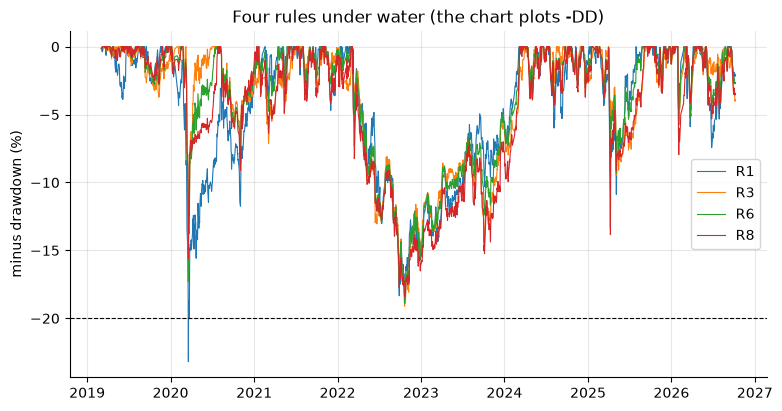

Problem 4: DD_t (%) [ 0.    0.    5.56 16.67 12.04  0.    5.45  0.  ]
Problem 4: MDD (%): 16.67   [book: 16.67]
Problem 4: B, the largest loss from W_0 (%): 10.00   [book: 10.00]


In [15]:
for k in RULES:
    hv, he = var_es(ret[k], U)
    nv_ = normal_var_es(ret[k].mean(), ret[k].std(ddof=0), U)[0]
    print(f"{k}: VaR 1% {100 * hv:.2f}, ES 1% {100 * he:.2f}, ES 2.5% {100 * var_es(ret[k], U2)[1]:.2f}, "
          f"normal VaR 1% {100 * nv_:.2f} (%)")


def dd_of(path):
    return 1 - path / np.maximum.accumulate(path)


def spells(path):
    lab = ["start", *rdates]
    dd = dd_of(path)
    it = int(np.argmax(dd))
    ip = int(np.argmax(path[: it + 1]))
    rec = next((j for j in range(it, len(path)) if path[j] >= path[ip] - EPS), None)
    under = path < np.maximum.accumulate(path) - EPS
    best, cur, best_end = 0, 0, 0
    for j, uw in enumerate(under):
        cur = cur + 1 if uw else 0
        if cur > best:
            best, best_end = cur, j
    return {"MDD %": 100 * dd[it], "peak": lab[ip], "trough": lab[it], "back": lab[rec] if rec else "open",
            "longest": best, "longest from": lab[best_end - best], "max DD0 %": 100 * max(0.0, 1 - path.min()),
            "on": lab[int(np.argmax(1 - path))], "end DD %": 100 * dd[-1]}


SP = {k: spells(paths[k]) for k in RULES}
print(pl.DataFrame([{"rule": k, **SP[k]} for k in RULES]).with_columns(pl.col("^.*%$").round(2)))
s1 = SP["R1"]
show("R1: MDD (%)", s1["MDD %"], ".2f", "23.19")
show("R1: max DD0 (%)", s1["max DD0 %"], ".2f", "10.24")
show("R1: recovery gain (1.17) (%)", s1["MDD %"] / (100 - s1["MDD %"]) * 100, ".2f", "30.19")
show("R2: MDD (%)", SP["R2"]["MDD %"], ".2f", "22.97")
show("R2: max DD0 (%)", SP["R2"]["max DD0 %"], ".2f", "0.39")
show("R2: the first purchase's cost (%)", 100 * (1 - paths["R2"][1]), ".3f", "0.142")

for k, c in zip(("R1", "R3", "R6", "R8"), ("C0", "C1", "C2", "C3")):
    plt.plot([date.fromisoformat(d) for d in rdates], -100 * dd_of(paths[k])[1:], lw=0.8, color=c, label=k)
plt.axhline(-20, ls="--", color="k", lw=0.8)
plt.ylabel("minus drawdown (%)")
plt.legend()
plt.title("Four rules under water (the chart plots -DD)")
plt.show()

wp = np.array([1.00, 1.08, 1.02, 0.90, 0.95, 1.10, 1.04, 1.12])         # Problem 4
print("Problem 4: DD_t (%)", np.round(100 * dd_of(wp), 2))
show("Problem 4: MDD (%)", 100 * dd_of(wp).max(), ".2f", "16.67")
show("Problem 4: B, the largest loss from W_0 (%)", 100 * (1 - wp.min()), ".2f", "10.00")

experiments 3 and 4 in 11 s
shape: (8, 8)
┌──────┬────────────────┬─────────────┬───────────────┬─────────────┬───────┬─────────┬────────────┐
│ rule ┆ perm median %  ┆ perm >= MDD ┆ boot median % ┆ boot >= MDD ┆ block ┆ largest ┆ atom count │
│ ---  ┆ ---            ┆ ---         ┆ ---           ┆ ---         ┆ ---   ┆ atom %  ┆ ---        │
│ str  ┆ f64            ┆ i64         ┆ f64           ┆ i64         ┆ i64   ┆ ---     ┆ i64        │
│      ┆                ┆             ┆               ┆             ┆       ┆ f64     ┆            │
╞══════╪════════════════╪═════════════╪═══════════════╪═════════════╪═══════╪═════════╪════════════╡
│ R1   ┆ 17.22          ┆ 1069        ┆ 20.72         ┆ 3305        ┆ 17    ┆ 22.43   ┆ 568        │
│ R2   ┆ 15.55          ┆ 557         ┆ 18.85         ┆ 2208        ┆ 21    ┆ 18.04   ┆ 812        │
│ R3   ┆ 15.15          ┆ 1723        ┆ 16.58         ┆ 2979        ┆ 22    ┆ 16.41   ┆ 1658       │
│ R4   ┆ 26.62          ┆ 1515        ┆ 23.66    

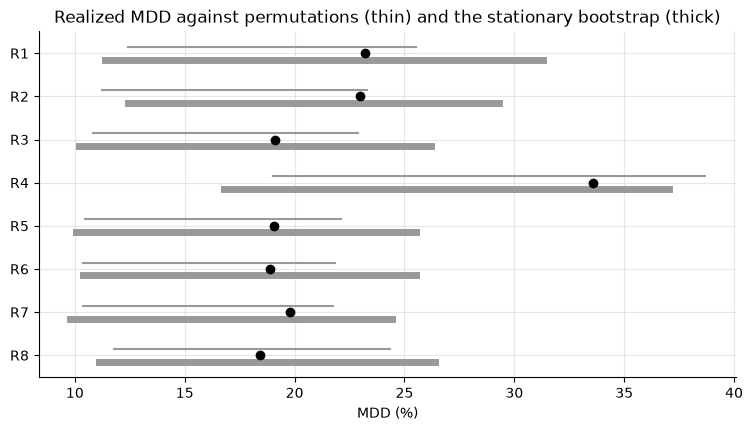

In [16]:
def mdd_rows(G, w0):
    Wp = w0 * np.cumprod(1 + G, axis=1)
    Wp = np.concatenate([np.ones((G.shape[0], 1)), np.full((G.shape[0], 1), w0), Wp], axis=1)
    return (1 - Wp / np.maximum.accumulate(Wp, axis=1)).max(axis=1)


def book_ell(xv):
    ob = optimal_block_length((xv - xv.mean()) ** 2)
    return round(float(ob.to_numpy()[0][0]))


t0 = time.perf_counter()
rng3, rng4 = np.random.default_rng([3, SEED]), np.random.default_rng([4, SEED])
MP = {k: np.concatenate([mdd_rows(rng3.permuted(np.tile(ret[k], (500, 1)), axis=1), paths[k][1]) for _ in range(20)])
      for k in RULES}
ELL, MB = {}, {}
for k in RULES:
    ELL[k] = book_ell(ret[k])
    MB[k] = np.concatenate([mdd_rows(ret[k][np.stack([stationary_idx(rng4, nR, ELL[k]) for _ in range(500)])],
                                     paths[k][1]) for _ in range(20)])
print(f"experiments 3 and 4 in {time.perf_counter() - t0:.0f} s")


def qv(v, u):
    return np.quantile(v, u, method="inverted_cdf")


res = []
for k in RULES:
    real = SP[k]["MDD %"] / 100
    vals, cnts = np.unique(np.round(MB[k], 10), return_counts=True)
    res.append({"rule": k, "perm median %": 100 * qv(MP[k], 0.5), "perm >= MDD": int(np.sum(MP[k] >= real - EPS)),
                "boot median %": 100 * qv(MB[k], 0.5), "boot >= MDD": int(np.sum(MB[k] >= real - EPS)),
                "block": ELL[k], "largest atom %": 100 * vals[np.argmax(cnts)], "atom count": int(cnts.max())})
print(pl.DataFrame(res).with_columns(pl.col("^.*%$").round(2)))
show("R1: permutation median (%)", res[0]["perm median %"], ".1f", "17.2")
show("R1: permutations at or above", res[0]["perm >= MDD"], ",", "1,069")
show("R1: bootstrap median (%)", res[0]["boot median %"], ".1f", "20.7")
show("R1: bootstrap at or above", res[0]["boot >= MDD"], ",", "3,305")
show("R2: permutations at or above", res[1]["perm >= MDD"], "d", "557")
print("R1's resamples equal to its MDD:", int(np.sum(np.abs(MB["R1"] - SP["R1"]["MDD %"] / 100) < 1e-10)))


def batch_se_med(v):                      # batch SE of a median, 20 consecutive batches of 500
    return np.std([qv(c, 0.5) for c in np.split(v, 20)]) / math.sqrt(20)


bse_m = [100 * batch_se_med(MP[k]) for k in RULES] + [100 * batch_se_med(MB[k]) for k in RULES if k not in ("R5", "R6")]
show("the medians' batch SEs, smallest (points)", min(bse_m), ".2f", "0.03")
show("  largest (points; none for R5's and R6's bootstrap medians, on an atom)", max(bse_m), ".2f", "0.13")
sh = [100 * math.sqrt(c / 1e4 * (1 - c / 1e4) / 1e4) for r_ in res for c in (r_["perm >= MDD"], r_["boot >= MDD"])]
show("the counts' SEs as shares of 10,000, smallest (points)", min(sh), ".1f", "0.2")
show("  largest (points)", max(sh), ".1f", "0.5")

for i, k in enumerate(RULES):
    yv = 8 - i
    plt.plot(100 * qv(MP[k], [0.05, 0.95]), [yv + 0.15] * 2, color="0.6", lw=1.5)
    plt.plot(100 * qv(MB[k], [0.05, 0.95]), [yv - 0.15] * 2, color="0.6", lw=5)
    plt.scatter([SP[k]["MDD %"]], [yv], color="k", zorder=3)
plt.yticks(range(1, 9), [f"R{9 - t}" for t in range(1, 9)])
plt.xlabel("MDD (%)")
plt.title("Realized MDD against permutations (thin) and the stationary bootstrap (thick)")
plt.show()

**Intraday falls (T5S; per-day statistics only).** On each of the three days, the TAIEX price index's largest log fall from its running peak, the 09:00:00 value (the previous close) included. Every change is a log change from 09:00:00. LM35 prints the closes and lows of 7 April 2025 and 5 August 2024; this lab prints them at its two decimals. No intraday path is shown.

In [17]:
for d in ("2025-04-07", "2024-08-05", "2020-03-19"):
    f_ = DATA / f"taiex5s_{d}.csv"
    if not f_.exists():
        print(f"{d}: {f_.name} is not in data/ (see the README); skipped")
        continue
    xx = pl.read_csv(f_, schema_overrides={"date": pl.Utf8, "TAIEX": pl.Float64})
    P = xx["TAIEX"].to_numpy()
    tt = xx["date"].str.slice(11, 8).to_list()
    assert tt[0] == "09:00:00" and tt[-1] == "13:30:00"
    lfall = np.log(np.maximum.accumulate(P) / P)
    jm, jl = int(np.argmax(lfall)), int(np.argmin(P))
    print(f"{d}: close {100 * np.log(P[-1] / P[0]):.2f}%, low {100 * np.log(P[jl] / P[0]):.2f}% at {tt[jl]}; "
          f"largest log fall from the running peak {100 * lfall[jm]:.2f}% (peak {tt[int(np.argmax(P[: jm + 1]))]}, "
          f"trough {tt[jm]})")

2025-04-07: close -10.20%, low -10.31% at 09:00:20; largest log fall from the running peak 10.31% (peak 09:00:00, trough 09:00:20)
2024-08-05: close -8.72%, low -8.96% at 13:03:10; largest log fall from the running peak 8.96% (peak 09:00:00, trough 13:03:10)
2020-03-19: close -6.01%, low -7.84% at 11:06:15; largest log fall from the running peak 7.84% (peak 09:00:00, trough 11:06:15)


## Part 9 — Extension: a 250-return backtest

Basel's 1996 rules ask for at least one year of observations. Declared in advance as one variant: rerun the HS and normal backtests with a trailing window of 250 returns on the same 4,609 forecast days, and compare the counts and the clustering with Exhibit 6 and Exhibit 7. This is a second trial on the same data, the kind of search that LM34 treats; it is out-of-sample, but its result is not a fresh test.

In [18]:
def var_short(m, t, w=250):
    wr = R[t - w:t]
    return var_es(wr, U)[0] if m == "HS" else normal_var_es(wr.mean(), wr.std(ddof=0), U)[0]


for m in ("HS", "N"):
    v250 = np.array([var_short(m, int(t)) for t in oos])
    hit = Ro < -v250 - EPS
    print(f"{m} with 250 returns: {int(hit.sum())} exceedances; with 1,231: {int(HIT[m].sum())}")
# your code: add the independence count and the 250-day windows of Basel's zones, and compare with the 1,231-return run

HS with 250 returns: 60 exceedances; with 1,231: 56
N with 250 returns: 102 exceedances; with 1,231: 110
